# 02 · Baseline & model statistik (ETS, SARIMAX, Prophet)

**Tujuan notebook:** membandingkan baseline sederhana dengan model statistik klasik secara adil, memakai **rolling-origin backtest** yang sama, lalu memahami di kelas demand mana model statistik membantu dan di mana tidak.

**Setup (semua dari `configs/config.yaml`):**
- 4 fold validasi (F1–F4), horizon 28 hari. Test set (d_1914–d_1941) **tidak dimuat** di notebook ini.
- Model statistik dilatih per series pada **730 hari terakhir** sebelum cutoff, dengan fit paralel di 16 core.
- Level agregat: 11 series (toko, 3 kategori, 7 departemen). Level item: **200 item sampel** (50 per kelas demand), dibandingkan *apple-to-apple* dengan baseline di 200 item yang sama.
- Metrik utama: **RMSSE** (agregat) dan **WRMSSE-lite** (item, dibobot revenue). Angka < 1 berarti lebih baik daripada tebakan naive 1-hari di data training.

Prediksi dihasilkan oleh `python -m scripts.run_backtest --model <nama> --level <item|agg>`. Notebook ini hanya membaca hasilnya dari `reports/results/`.

In [1]:
import json

import pandas as pd
import plotly.io as pio

from forecasting.config import load_config, resolve_path
from forecasting.evaluation.metrics import compute_scales, rmsse_per_series
from forecasting.validation.backtest import generate_folds, get_test_fold, load_level_data
from forecasting.viz import plots

pio.renderers.default = "png"
pio.renderers["png"].width = 1000
pd.set_option("display.float_format", "{:,.3f}".format)

config = load_config()
folds = generate_folds(config)
RESULTS = resolve_path(config, "results")
board = pd.read_csv(RESULTS / "leaderboard_cv.csv")
agg = load_level_data(config, "agg")  # d <= 1913: test window never loaded
items = load_level_data(config, "item")
classes = pd.read_parquet(resolve_path(config, "processed") / "item_classes.parquet")
sample = pd.read_csv(resolve_path(config, "processed") / "stat_sample_items.csv")

## 1 · Desain validasi: rolling-origin backtest

Setiap fold memakai **semua data sampai cutoff** untuk training (*expanding window*), lalu memprediksi 28 hari berikutnya. Cutoff digeser 28 hari setiap fold, sehingga model diuji di 4 periode berbeda (Januari–April 2016). Skor akhir = rata-rata ± standar deviasi 4 fold.

**Kenapa bukan random split?** Kalau data dibagi acak, model ikut melihat hari-hari *sesudah* hari yang diprediksi (leakage), sehingga skor terlihat bagus padahal di dunia nyata masa depan tidak pernah tersedia. Backtest meniru kondisi asli: latih dengan masa lalu, uji di masa depan.

Blok merah (TEST) hanya akan disentuh **sekali** di Fase 6, setelah semua pemilihan model selesai.

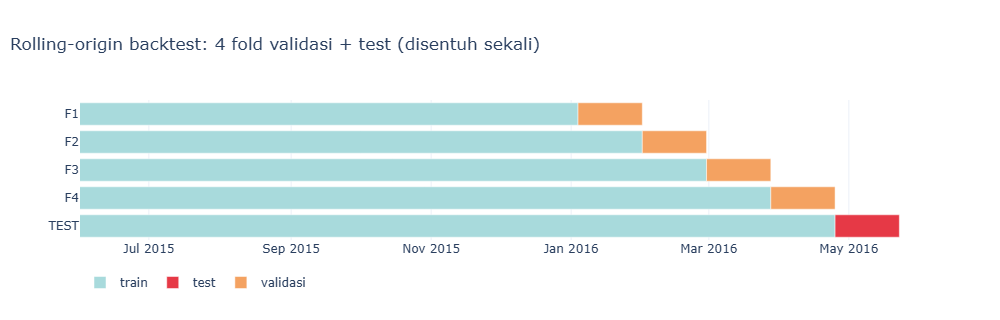

,fold,train_start,train_end,valid_start,valid_end
0,F1,2011-01-29,2016-01-03,2016-01-04,2016-01-31
1,F2,2011-01-29,2016-01-31,2016-02-01,2016-02-28
2,F3,2011-01-29,2016-02-28,2016-02-29,2016-03-27
3,F4,2011-01-29,2016-03-27,2016-03-28,2016-04-24
4,TEST,2011-01-29,2016-04-24,2016-04-25,2016-05-22


In [2]:
day = agg.drop_duplicates("d").set_index("d")["date"]
first_date = day.iloc[0]
test = get_test_fold(config)
test_dates = pd.date_range(day.iloc[-1] + pd.Timedelta(days=1), periods=test.horizon)
fold_tbl = pd.DataFrame(
    [
        {
            "fold": f.name,
            "train_start": first_date,
            "train_end": day[f.train_end],
            "valid_start": day[f.valid_start],
            "valid_end": day[f.valid_end],
        }
        for f in folds
    ]
    + [
        {
            "fold": "TEST",
            "train_start": first_date,
            "train_end": day[test.train_end],
            "valid_start": test_dates[0],
            "valid_end": test_dates[-1],
        }
    ]
)
fig = plots.plot_backtest_folds(
    fold_tbl, title="Rolling-origin backtest: 4 fold validasi + test (disentuh sekali)"
)
fig.update_xaxes(range=[pd.Timestamp("2015-06-01"), test_dates[-1] + pd.Timedelta(days=10)])
fig.show()
plots.save_png(fig, "09_backtest_folds", config)
fold_tbl.assign(**{c: fold_tbl[c].dt.date for c in fold_tbl.columns if c != "fold"})

## 2 · Dekomposisi STL: apa saja komponen datanya?

> **STL** (*Seasonal-Trend decomposition using Loess*) memecah series menjadi tiga bagian: **trend** (arah jangka panjang), **seasonal** (pola berulang, di sini period 7 = mingguan), dan **residual** (sisa yang tidak bisa dijelaskan keduanya).

**Insight:** komponen seasonal mingguan berukuran ratusan unit per hari dan amplitudonya stabil sepanjang 2 tahun. Trend bergerak pelan, naik-turun mengikuti musim tahunan, tanpa lonjakan permanen. Residual masih memuat lonjakan tajam di sekitar hari libur, yaitu bagian yang tidak bisa ditangkap model musiman murni.

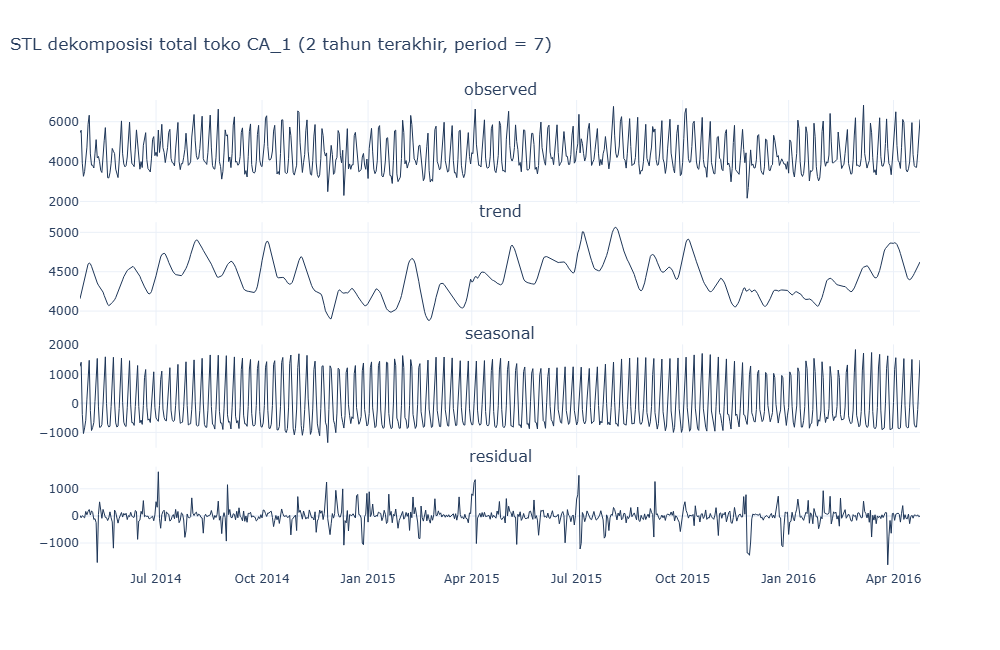

WindowsPath('C:/Projects/demand-forecasting-project/reports/figures/10_stl_store.png')

In [3]:
store = agg[agg["series_id"] == "CA_1"].set_index("date")["sales"].astype(float)
last2y = store.loc[store.index > store.index.max() - pd.Timedelta(days=730)]
last2y = last2y.where(
    agg.drop_duplicates("d").set_index("date")["is_closed"].reindex(last2y.index) == 0
)
last2y = last2y.interpolate()
fig = plots.plot_stl(
    last2y, period=7, title="STL dekomposisi total toko CA_1 (2 tahun terakhir, period = 7)"
)
fig.show()
plots.save_png(fig, "10_stl_store", config)

## 3 · ACF/PACF: dasar pemilihan orde SARIMA

> **ACF** (*autocorrelation function*) = korelasi series dengan dirinya sendiri yang digeser *k* hari. **PACF** (*partial ACF*) = korelasi di lag *k* setelah pengaruh lag-lag yang lebih pendek dihilangkan. Batang di luar garis putus-putus berarti signifikan (±1,96/√n).
>
> **Stasioner** = rata-rata dan variasi series tidak berubah seiring waktu. ARIMA butuh data stasioner, dan caranya adalah **differencing** (mengurangi nilai hari ini dengan nilai *k* hari sebelumnya).

**Data asli:** ACF memuncak di lag **7, 14, 21, 28, 35** (±0,75) dan hampir tidak meluruh. Ini tanda pola mingguan yang kuat sekaligus **tidak stasioner secara musiman**, sehingga butuh *seasonal differencing* (**D = 1**, lag 7). Inilah alasan **seasonal period = 7**.

**Setelah differencing (lag 7 lalu lag 1):** pola mingguan hilang. Yang tersisa adalah lonjakan negatif besar di **lag 1** (−0,4) dan **lag 7** (−0,55) pada ACF, sedangkan PACF meluruh perlahan di kelipatan 7. Pola ini khas komponen **MA(1) + seasonal MA(1)** (model "airline").

**Hasil grid AIC (216 kombinasi, hanya di data training F1):** orde terpilih untuk agregat hampir semuanya **d = 1, D = 1, q = 2, Q = 1**, konsisten dengan bacaan ACF/PACF di atas. Orde dikunci untuk F2–F4 (tidak dipilih ulang dengan melihat fold lain). Untuk item, satu orde dipilih per kelas demand berdasarkan jumlah AIC 10 item per kelas.

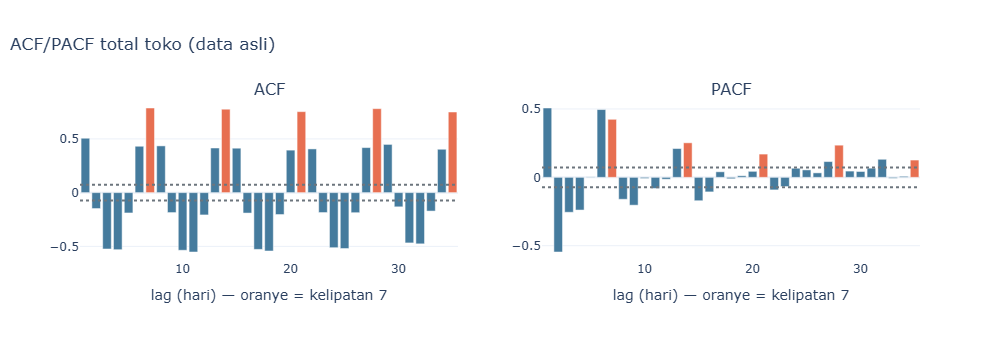

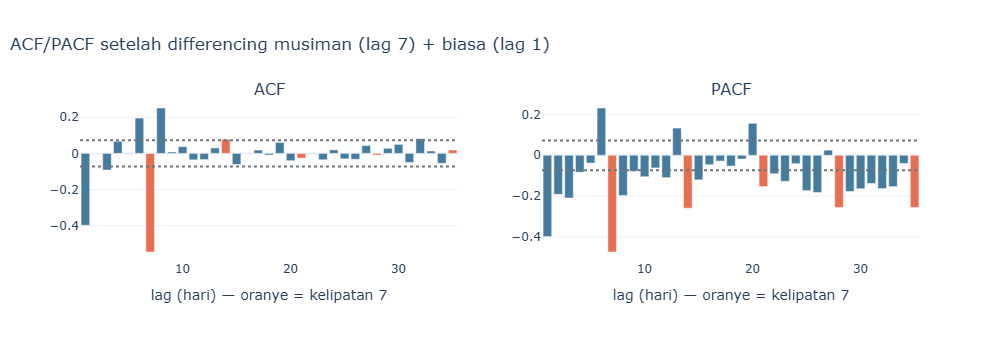

WindowsPath('C:/Projects/demand-forecasting-project/reports/figures/11b_acf_pacf_diff.png')

In [4]:
fig = plots.plot_acf_pacf(last2y, lags=35, title="ACF/PACF total toko (data asli)")
fig.show()
plots.save_png(fig, "11a_acf_pacf_raw", config)
diffed = last2y.diff(7).diff(1).dropna()
fig = plots.plot_acf_pacf(
    diffed, lags=35, title="ACF/PACF setelah differencing musiman (lag 7) + biasa (lag 1)"
)
fig.show()
plots.save_png(fig, "11b_acf_pacf_diff", config)

In [5]:
orders = json.loads((RESULTS / "sarima_orders.json").read_text())
pd.concat(
    [
        pd.Series(orders["agg"], name="order")
        .rename_axis("series")
        .reset_index()
        .assign(level="agg"),
        pd.Series(orders["item_class"], name="order")
        .rename_axis("series")
        .reset_index()
        .assign(level="item (per kelas)"),
    ]
)[["level", "series", "order"]]

,level,series,order
0,agg,CA_1,"(2,1,2)(1,1,1)"
1,agg,FOODS,"(1,1,2)(0,1,1)"
2,agg,FOODS_1,"(1,1,2)(1,1,1)"
3,agg,FOODS_2,"(1,1,2)(1,1,1)"
4,agg,FOODS_3,"(2,1,2)(0,1,1)"
5,agg,HOBBIES,"(0,1,2)(1,1,1)"
6,agg,HOBBIES_1,"(1,1,2)(1,1,1)"
7,agg,HOBBIES_2,"(0,1,2)(0,1,1)"
8,agg,HOUSEHOLD,"(2,1,2)(0,1,1)"
9,agg,HOUSEHOLD_1,"(0,1,2)(1,1,1)"


## 4 · Leaderboard CV

**Level agregat:** ketiga model statistik **jauh mengalahkan** benchmark Seasonal Naive (RMSSE 0,927).
- **SARIMAX terbaik: RMSSE 0,660 ± 0,028** (−29% vs Seasonal Naive). WAPE turun dari 12,7% menjadi 8,9%, dan std antar-fold paling kecil (paling stabil).
- Prophet 0,685 ± 0,066 dan ETS 0,714 ± 0,082 juga jauh di atas baseline.
- Bias semua model sedikit negatif (−3%), artinya cenderung *under-forecast*.

**Level item (200 item sampel):** selisihnya **jauh lebih tipis**.
- **SARIMAX 0,727 ± 0,040** dan **ETS 0,738 ± 0,048** mengalahkan benchmark Moving Average 28 (0,768), masing-masing −5,3% dan −3,9%.
- **Prophet (0,812) justru kalah dari MA28**, meskipun 7× lebih lambat.
- Pada RMSSE tanpa bobot, SARIMAX/ETS (0,664) hampir sama dengan MA28 (0,677). Jadi keunggulan model statistik datang terutama dari **item bernilai tinggi**, yang biasanya lebih sering laku.
- Biaya: SARIMAX butuh 119 dtk untuk 200 item × 4 fold, sedangkan MA28 < 6 dtk.

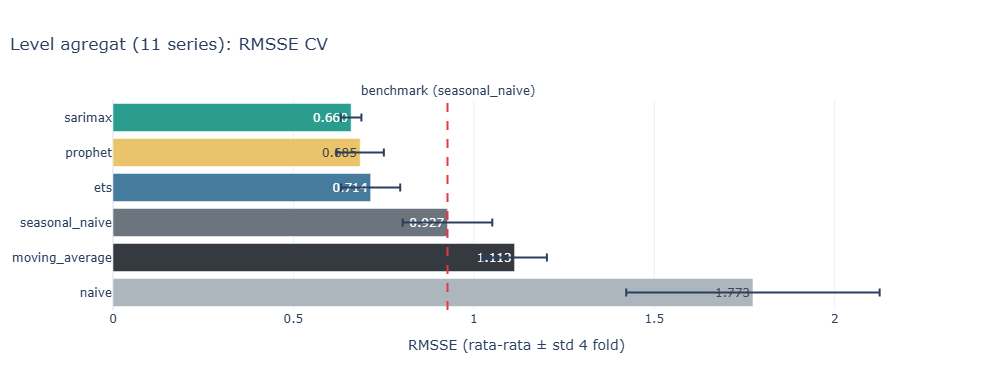

,model,rmsse_mean,rmsse_std,mase_mean,wape_mean,bias_mean,runtime_sec_total
0,sarimax,0.660,0.028,0.671,0.089,-0.035,15.216
1,prophet,0.685,0.066,0.741,0.095,-0.027,6.455
2,ets,0.714,0.082,0.749,0.089,-0.028,7.451
3,seasonal_naive,0.927,0.124,0.946,0.127,-0.038,0.045
4,moving_average,1.113,0.090,1.184,0.183,-0.023,0.039
5,naive,1.773,0.351,2.051,0.328,0.241,0.036


In [6]:
cols = [
    "model",
    "rmsse_mean",
    "rmsse_std",
    "mase_mean",
    "wape_mean",
    "bias_mean",
    "runtime_sec_total",
]
# later phases add LightGBM rows to the leaderboard; this notebook covers these models only
NB02_MODELS = ["naive", "seasonal_naive", "moving_average", "ets", "sarimax", "prophet"]
board = board[board["model"].isin(NB02_MODELS)]
b_agg = board[board["level"] == "agg"]
fig = plots.plot_leaderboard(
    b_agg, "rmsse", benchmark="seasonal_naive", title="Level agregat (11 series): RMSSE CV"
)
fig.show()
plots.save_png(fig, "12_leaderboard_agg", config)
b_agg[cols].reset_index(drop=True)

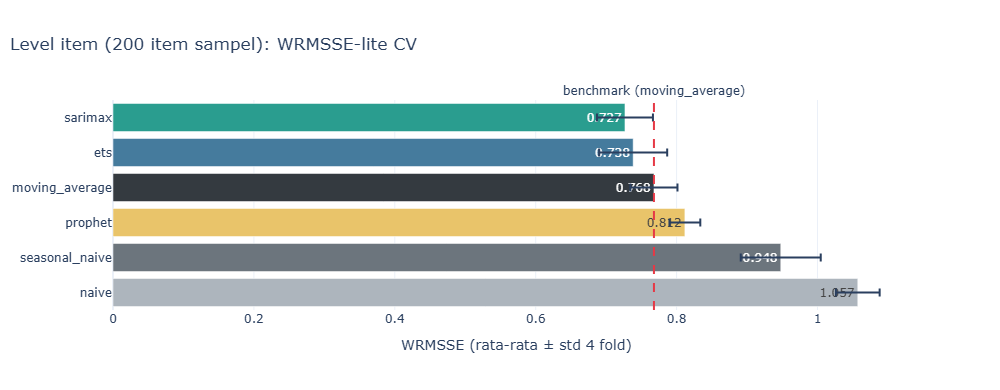

,model,wrmsse_mean,wrmsse_std,rmsse_mean,rmsse_std,mase_mean,wape_mean,bias_mean,runtime_sec_total
0,sarimax,0.727,0.040,0.664,0.016,0.840,0.613,-0.009,119.467
1,ets,0.738,0.048,0.665,0.023,0.834,0.618,-0.035,8.289
2,moving_average,0.768,0.033,0.677,0.014,0.849,0.634,-0.022,5.623
3,prophet,0.812,0.022,0.737,0.013,0.924,0.687,-0.035,38.420
4,seasonal_naive,0.948,0.057,0.853,0.028,0.996,0.754,-0.053,4.597
5,naive,1.057,0.031,0.894,0.027,1.121,0.885,0.231,6.176


In [7]:
b_item = board[(board["level"] == "item") & (board["subset"] == "stat_sample")]
fig = plots.plot_leaderboard(
    b_item,
    "wrmsse",
    benchmark="moving_average",
    title="Level item (200 item sampel): WRMSSE-lite CV",
)
fig.show()
plots.save_png(fig, "13_leaderboard_item", config)
b_item[["model", "wrmsse_mean", "wrmsse_std", *cols[1:]]].reset_index(drop=True)

## 5 · Di kelas demand mana model statistik membantu?

RMSSE per item dihitung per fold (skala dari data training fold itu sendiri), lalu dirata-rata per kelas demand.

**Insight:**
- **Smooth & erratic** (item yang hampir setiap hari laku): SARIMAX/ETS unggul jelas atas MA28. Smooth 0,714 vs 0,750 (−5%), erratic 0,616 vs 0,644 (−4%). Pola mingguan item ini cukup kuat untuk dimanfaatkan.
- **Intermittent** (72% populasi item): ETS, SARIMAX, dan MA28 **praktis seri** (0,663–0,664). Model statistik tidak menambah apa-apa, karena dengan banyak hari nol, pola mingguannya tenggelam dalam noise.
- **Lumpy:** ETS (0,647) ≈ MA28 (0,650), sedangkan SARIMAX (0,661) sedikit lebih buruk.
- **Prophet** paling buruk di antara model non-naive di **semua** kelas (0,71–0,77). Trend dan seasonality aditifnya terlalu kaku untuk data kecil yang banyak nol.
- **Seasonal Naive** paling buruk di semua kelas. Menyalin satu hari minggu lalu sama dengan menyalin noise.

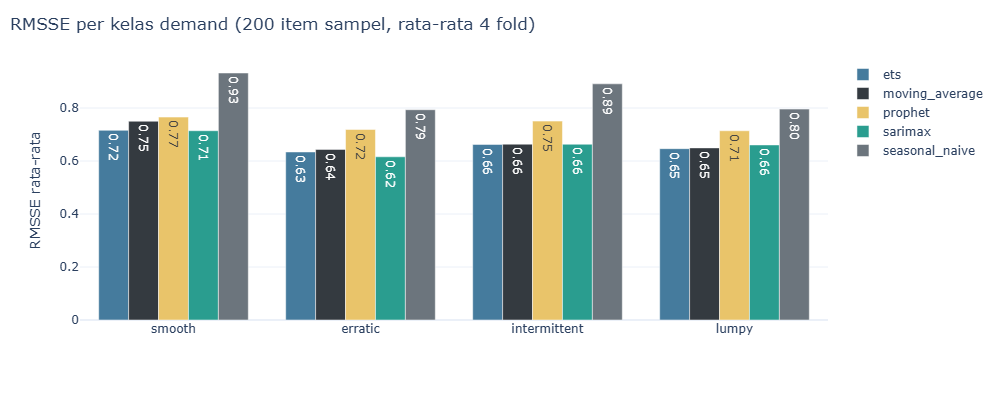

model,seasonal_naive,moving_average,ets,sarimax,prophet,best
demand_class,,,,,,
smooth,0.932,0.750,0.716,0.714,0.766,sarimax
erratic,0.794,0.644,0.634,0.616,0.719,sarimax
intermittent,0.891,0.664,0.663,0.663,0.751,ets
lumpy,0.796,0.650,0.647,0.661,0.714,ets


In [8]:
MODELS = ["seasonal_naive", "moving_average", "ets", "sarimax", "prophet"]
ids = set(sample["item_id"])
rows = []
for model in MODELS:
    preds = pd.read_parquet(RESULTS / "preds" / f"{model}_item.parquet")
    preds = preds[preds["series_id"].astype(str).isin(ids) & (preds["is_closed"] == 0)]
    for f in folds:
        train = items[(items["d"] <= f.train_end) & items["series_id"].astype(str).isin(ids)]
        r = rmsse_per_series(preds[preds["fold"] == f.name], compute_scales(train, f.train_end))
        rows.append(r.rename("rmsse").reset_index().assign(model=model, fold=f.name))
per_item = pd.concat(rows).merge(sample, left_on="series_id", right_on="item_id")
by_class = per_item.groupby(["demand_class", "model"], observed=True)["rmsse"].mean().reset_index()
by_class["demand_class"] = pd.Categorical(
    by_class["demand_class"], ["smooth", "erratic", "intermittent", "lumpy"]
)
by_class = by_class.sort_values(["demand_class", "model"])
fig = plots.plot_metric_by_group(
    by_class,
    "demand_class",
    "rmsse",
    axis_title="RMSSE rata-rata",
    title="RMSSE per kelas demand (200 item sampel, rata-rata 4 fold)",
)
fig.show()
plots.save_png(fig, "14_rmsse_by_class", config)
pivot = by_class.pivot(index="demand_class", columns="model", values="rmsse")[MODELS]
pivot.assign(best=pivot.idxmin(axis=1))

## 6 · Contoh forecast vs aktual (fold F4)

> **Catatan data:** contoh per item disamarkan (nama generik, hari relatif, dan indeks dengan rata-rata = 100) karena aturan kompetisi M5 tidak mengizinkan publikasi datanya.

Item dipilih secara **otomatis sebagai item median** di kelasnya (berdasarkan RMSSE SARIMAX di F4), bukan dipilih manual supaya kelihatan bagus.

**Insight:** di item smooth, SARIMAX/ETS/Prophet menangkap pola naik-turun mingguan, sedangkan MA28 berupa garis datar. Tetapi lonjakan individual tidak bisa diprediksi model mana pun. Di item lumpy, terlihat kelemahan masing-masing model: ETS terlalu tinggi karena level-nya terbawa lonjakan terakhir sebelum cutoff, Prophet terlalu rendah, dan SARIMAX berada di tengah. Pada item seperti ini, perbedaan antar-model kecil dibanding besarnya noise harian.

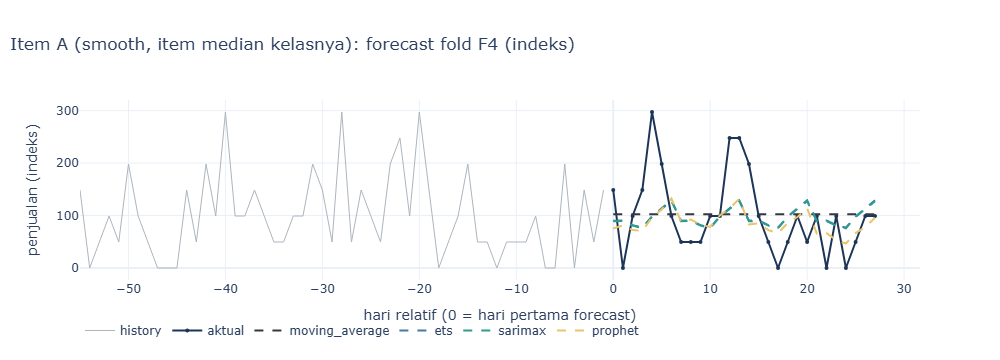

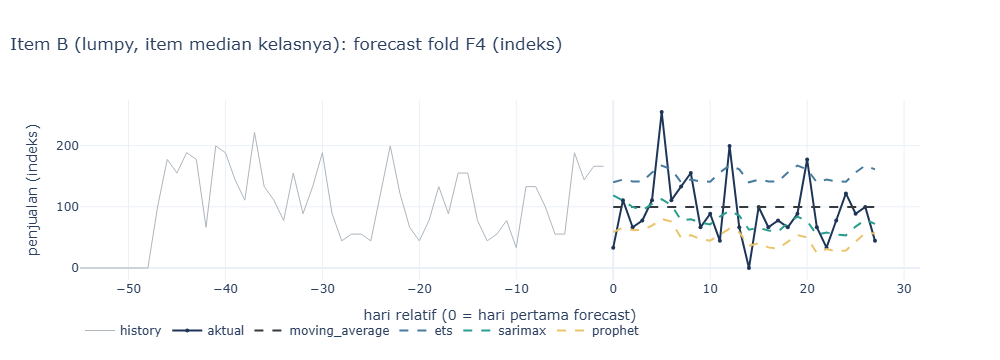

In [9]:
from forecasting.viz.anonymize import index_base, item_label, relative_days, to_index

f4 = folds[-1]
hist_from = f4.train_end - 55


def show_item(cls: str, name: str, position: int) -> None:
    pool = per_item[
        (per_item["demand_class"] == cls)
        & (per_item["fold"] == "F4")
        & (per_item["model"] == "sarimax")
    ].sort_values("rmsse")
    item = pool.iloc[len(pool) // 2]["series_id"]  # median item of the class (not cherry-picked)
    s = items[items["series_id"].astype(str) == item]
    history = s[(s["d"] > hist_from) & (s["d"] <= f4.train_end)][["date", "sales"]]
    actual = s[s["d"].between(f4.valid_start, f4.valid_end)][["date", "sales"]].rename(
        columns={"sales": "y_true"}
    )
    parts = []
    for model in ["moving_average", "ets", "sarimax", "prophet"]:
        p = pd.read_parquet(RESULTS / "preds" / f"{model}_item.parquet")
        p = p[(p["series_id"].astype(str) == item) & (p["fold"] == "F4")]
        parts.append(p.merge(s[["d", "date"]], on="d")[["date", "y_pred"]].assign(model=model))
    preds = pd.concat(parts)
    # one common base (history mean) and one common day 0 (first forecast day)
    base, start = index_base(history["sales"]), actual["date"].iloc[0]
    for frame, col in [(history, "sales"), (actual, "y_true"), (preds, "y_pred")]:
        frame[col] = to_index(frame[col].to_numpy(dtype=float), base)
        frame["date"] = relative_days(frame["date"], start)
    fig = plots.plot_forecast_vs_actual(
        history,
        actual,
        preds,
        title=f"{item_label(position)} ({cls}, item median kelasnya): forecast fold F4 (indeks)",
    )
    fig.update_xaxes(title_text="hari relatif (0 = hari pertama forecast)")
    fig.update_yaxes(title_text="penjualan (indeks)")
    fig.show()
    plots.save_png(fig, name, config)


show_item("smooth", "15a_forecast_smooth_item", 0)
show_item("lumpy", "15b_forecast_lumpy_item", 1)

## Key findings → implikasi ke Fase 5 (LightGBM)

| # | Temuan | Implikasi |
|---|---|---|
| 1 | Agregat: SARIMAX RMSSE **0,660** (−29% vs Seasonal Naive), paling stabil antar-fold | Ini **target baru di level agregat** yang harus dikalahkan LightGBM (lewat agregasi bottom-up). |
| 2 | Item: SARIMAX **0,727** / ETS 0,738 vs MA28 0,768 (−4 s/d −5%) | Target di level item (200 sampel): **WRMSSE < 0,727**. Untuk semua 3.049 item, benchmark tetap MA28 (0,841). |
| 3 | Gain model statistik hanya di item smooth/erratic; di intermittent/lumpy semua model ≈ MA28 | LightGBM harus membuktikan diri **justru di intermittent/lumpy**, yaitu 89% item. Objective **tweedie/poisson** dan fitur `zero_run_len` dirancang untuk itu. |
| 4 | Prophet kalah dari MA28 di level item dan 7× lebih lambat | Prophet tidak dibawa sebagai kandidat final level item. Di level agregat Prophet masih kompetitif (0,685). |
| 5 | ACF: pola mingguan dominan, D = 1 dan MA musiman | Fitur `day_of_week` serta lag kelipatan 7 (`lag_28, lag_35, ...`) relevan untuk LightGBM. |
| 6 | Residual masih memuat lonjakan hari libur | Fitur event dan SNAP (yang tidak dipakai ETS/SARIMAX) berpeluang memberi keunggulan pada LightGBM. |
| 7 | Runtime: SARIMAX 119 dtk (200 item); MA28 < 6 dtk | Menjalankan SARIMAX untuk 3.049 item × 4 fold butuh ±30 menit, masih layak kalau dibutuhkan di Fase 6. |